# Handwritten Digit Recognition using TensorFlow/Keras
**Goal:** Train a neural network to classify handwritten digits (0–9) using the MNIST dataset.

**What you'll practice:** loading data, preprocessing, building a model, training, evaluating, predictions, and saving the model.

> Run each cell in order. Record the accuracy you actually get; don't guess or copy a result you haven't measured.

## 1. Import libraries

In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 2. Load the MNIST dataset
MNIST contains 28×28 grayscale images of handwritten digits. The data is split into training and test sets.

In [3]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


## 3. View sample images

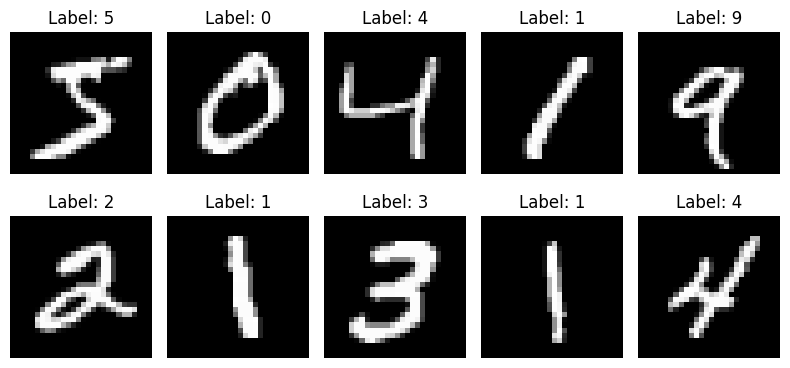

In [4]:
plt.figure(figsize=(8, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

## 4. Preprocess the data
Pixel values are originally 0–255. Scaling them to 0–1 usually makes neural-network training easier.

In [5]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Pixel range after scaling:", x_train.min(), "to", x_train.max())

Pixel range after scaling: 0.0 to 1.0


## 5. Build the model
Flatten turns each 28×28 image into 784 numbers. Dense layers learn patterns. The output has 10 scores, one for each digit.

In [6]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Train the model
This may take a few minutes. The validation split holds out part of the training data to check progress during training.

In [7]:
history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9078 - loss: 0.3138 - val_accuracy: 0.9637 - val_loss: 0.1291
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9543 - loss: 0.1529 - val_accuracy: 0.9732 - val_loss: 0.0922
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9651 - loss: 0.1161 - val_accuracy: 0.9760 - val_loss: 0.0830
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9707 - loss: 0.0926 - val_accuracy: 0.9783 - val_loss: 0.0709
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9757 - loss: 0.0781 - val_accuracy: 0.9760 - val_loss: 0.0767


## 7. Evaluate on unseen test images
Use the measured result from this cell in your README and resume discussion.

In [8]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4%}")

Test loss: 0.0836
Test accuracy: 97.4200%


## 8. Plot training progress

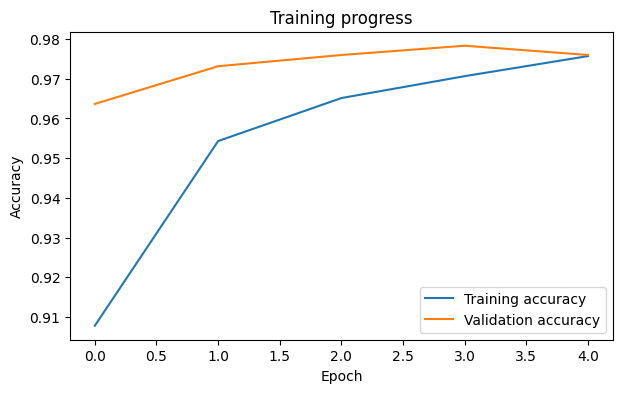

In [11]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Training progress")
plt.show()

## 9. Predict a few test images

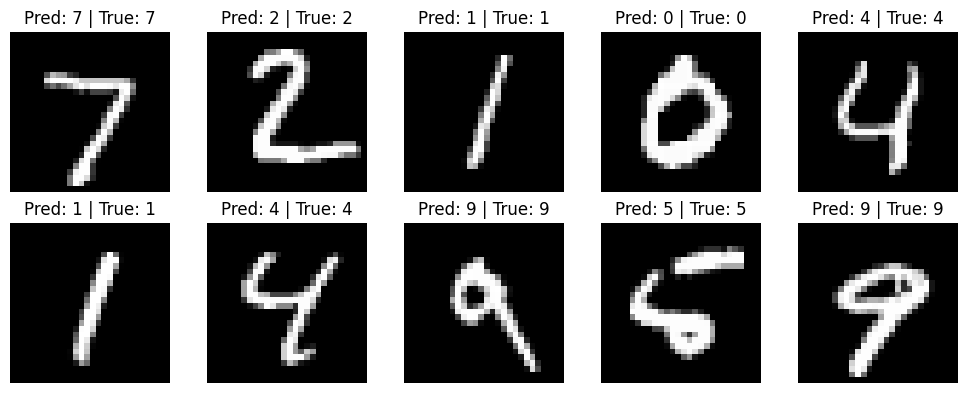

Predictions: [7 2 1 0 4 1 4 9 5 9]
Actual labels: [7 2 1 0 4 1 4 9 5 9]


In [12]:
probabilities = model.predict(x_test[:10], verbose=0)
predictions = np.argmax(probabilities, axis=1)

plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title(f"Pred: {predictions[i]} | True: {y_test[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

print("Predictions:", predictions)
print("Actual labels:", y_test[:10])

## 10. Inspect one prediction and confidence

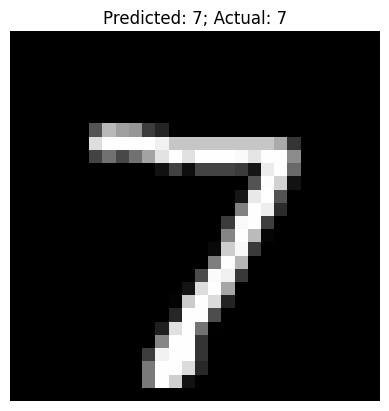

Predicted digit: 7
Confidence for predicted digit: 99.99%


In [13]:
index = 0
probs = model.predict(x_test[index:index+1], verbose=0)[0]
predicted_digit = int(np.argmax(probs))

plt.imshow(x_test[index], cmap="gray")
plt.title(f"Predicted: {predicted_digit}; Actual: {y_test[index]}")
plt.axis("off")
plt.show()

print("Predicted digit:", predicted_digit)
print("Confidence for predicted digit:", f"{probs[predicted_digit]:.2%}")

## 11. Save the trained model

In [14]:
model.save("mnist_digit_recognition.keras")
print("Saved model: mnist_digit_recognition.keras")

Saved model: mnist_digit_recognition.keras


## 12. Optional challenge: improve it
Try one change at a time and compare the **test accuracy**:
- Change epochs from 5 to 8.
- Change the hidden layer size from 128 to 64 or 256.
- Add a second Dense layer, for example `Dense(64, activation="relu")` before the output layer.

Write down your baseline and new result. Don't claim improvement unless the measured result supports it.

## Resume-ready project summary (fill in after completing)
**Handwritten Digit Recognition | Python, TensorFlow, Keras, NumPy**
- Built a neural-network classifier for the MNIST handwritten digit dataset.
- Preprocessed image pixel values and trained the model using TensorFlow/Keras.
- Evaluated the model on held-out test data; achieved **[insert your measured test accuracy]** test accuracy.
- Saved the trained model and visualized predictions and training progress.

## GitHub README checklist
- Project overview and goal
- Dataset source: built-in `tf.keras.datasets.mnist`
- Tools and libraries
- How to run the notebook in Google Colab
- Your actual test accuracy
- A screenshot of sample predictions
- What you learned and what you would improve